# Project 1: Friends Scripts: Joey Tribbiani
**Text Mining (G00C8A & G00C8B)**

**Character analysed:** Joey Tribbiani  
**Data:** `friends.csv`, the scripts of the Friends seasons (columns `Text`, `Speaker`, `Episode`, `Season`, `Show`).

1. imports the libraries 
2. downloads the NLTK data that is needed (stopwords and the Punkt sentence/word tokeniser)
3. creates the Porter stemmer and the NLTK stopword list
4. reads `friends.csv`
5. defines `name_alias_map`: nicknames and surnames are mapped to one name (rach → rachel) so that variants of a name are counted as the same person
6. defines `contractions_dict`: slang and contractions are mapped to full words (gonna → going to) so that tokenisation does not break them 
7. defines `spoken_fillers`: list of interjections and generic words (hey, yeah, know, like) are added to the NLTK stopwords as `custom_stopwords`. This is a subjective choice and it is used only in Q3 and Q4, not in Q1 or Q2, where every spoken word or noun counts
8. helper functions:
   - `strip_stage_directions`: removes text in `( )` and `[ ]` and collapses whitespace
   - `expand_contractions`: lower-cases, normalises curly quotes, expands contractions and repairs dropped g's (walkin' → walking)
   - `stem_to_lexeme_mapper`: maps each Porter stem back to its most frequent original word so tables and clouds show readable words

In [7]:
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import sent_tokenize, word_tokenize

import spacy
import seaborn as sns

for resource in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(resource, quiet=True)

stemmer = PorterStemmer()
nltk_stopwords = set(stopwords.words("english"))

df_raw = pd.read_csv("friends.csv")

# alias mapping since the same person could have different variations of their name
name_alias_map = {
    "rach": "rachel",
    "pheebs": "phoebe","phoebs": "phoebe",
    "chan": "chandler", "bing": "chandler",
    "mon": "monica",
    "joe": "joey", "joseph": "joey","tribbiani": "joey","joey tribbiani":"joey"}

# dialogue  mapping so conversational slang is not misinterpreted
contractions_dict = {
    r"\bc'mon\b": "come on", r"\bgonna\b": "going to", r"\bwanna\b": "want to",
    r"\bdunno\b": "do not know", r"\bgotta\b": "got to",    r"\bain't\b": "is not", r"\bdon't\b": "do not", r"\bdoesn't\b": "does not",
    r"\bdidn't\b": "did not", r"\bcan't\b": "cannot", r"\bwon't\b": "will not",
    r"\bisn't\b": "is not", r"\baren't\b": "are not", r"\bcouldn't\b": "could not",
    r"\bwouldn't\b": "would not", r"\bshouldn't\b": "should not", r"\bi'm\b": "i am",
    r"\byou're\b": "you are", r"\bhe's\b": "he is", r"\bshe's\b": "she is",
    r"\bit's\b": "it is", r"\bwe're\b": "we are", r"\bthey're\b": "they are",r"(?<!\w)'em\b": "them",
    r"\bthere's\b": "there is", r"\bthat's\b": "that is", r"\bwhat's\b": "what is", r"\bwho's\b": "who is"}

#  fillers and dialogue noise stopwords
spoken_fillers = {"hey", "yeah", "know", "oh", "ohh", "look", "right", "like", "get", "okay", "go",
    "well", "na", "uh", "got", "ok", "gon", "wan", "think", "mean", "say", "see", "ya", "x",
    "come", "going", "want", "thing", "things", "something", "us", "would", "could", "s",
    "take", "tell", "make", "let", "uhh", "yeahs", "ooh", "ah", "huh", "hi", "yes", "nah",
    "umm", "uhm", "woah", "alright", "somethin", "dunno", "naa", "noooo", "hmm", "e",
    "dude", "man", "guys", "guy", "one", "really", "back", "said", "y'know"}

# add these also to the more general stopword list 
custom_stopwords = nltk_stopwords.union(spoken_fillers)

def strip_stage_directions(text):
    if not isinstance(text, str): return ""
    text = re.sub(r"\([^)]*\)", "", text)
    text = re.sub(r"\[[^\]]*\]", "", text)
    return re.sub(r"\s+", " ", text).strip()

def fix_dropped_g(t):
    return re.sub(r"\b(\w{2,})in'(?=\W|$)", r"\1ing", t)

def expand_contractions(text):
    t = str(text).lower().replace("’", "'").replace("‘", "'")
    for pattern, replacement in contractions_dict.items():
        t = re.sub(pattern, replacement, t)
    return fix_dropped_g(t)

def stem_to_lexeme_mapper(stemmed_tokens, original_tokens):
    mapping = defaultdict(Counter)
    for stem, orig in zip(stemmed_tokens, original_tokens): mapping[stem][orig.lower()] += 1
    stem2lexeme = {}
    for stem, counts in mapping.items(): stem2lexeme[stem] = counts.most_common(1)[0][0]
    return stem2lexeme

## Preprocessing

In [8]:
# data checks 
spk = df_raw["Speaker"].fillna("").str.strip()
print("where Joey is the speaker :", int((spk.str.lower() == "joey").sum()))
other = spk[spk.str.contains("joey", case=False) & (spk.str.lower() != "joey")]
print("labels that contain 'joey' but not his lines):", other.value_counts().head(8).to_dict())
print("episodes per season in the file:", df_raw.groupby("Season")["Episode"].nunique().to_dict(), "-> total", df_raw[["Season", "Episode"]].drop_duplicates().shape[0])

where Joey is the speaker : 8047
labels that contain 'joey' but not his lines): {'Chandler and Joey': 16, 'Joey and Chandler': 13, "Joey's Hand Twin": 13, 'Joey/Drake': 13, 'Joey and Ross': 10, 'CHANDLER and JOEY': 6, 'Joey’s Sister': 6, "Joey's Doctor": 6}
episodes per season in the file: {'Season-01': 24, 'Season-02': 23, 'Season-03': 25, 'Season-04': 23, 'Season-05': 23, 'Season-06': 23, 'Season-07': 23, 'Season-08': 23, 'Season-09': 23, 'Season-10': 15} -> total 225


**Data checks**
- Joey has 8,047 lines under the label `Joey`. Top 8 other labels that contain "joey" ("Joey's Hand Twin", "Joey/Drake") add up to only 83 lines (about 1% of 8,047), so **only the label `Joey` is used**.
- The CSV contains **225 episodes** (Season 10 only 15) so the dataset does not contain all of them

### Which preprocessing step where, and why
| Step | Q1 | Q2 | Q3 | Q4 |
|---|---|---|---|---|
| remove stage directions ( ) / [ ] | yes | yes | yes | yes |
| remove punctuation | no (needed to split sentences) | no (NER needs the original text) | yes (`isalpha`), after expanding contractions | yes (same tokens as Q3) |
| lower case | no | no (capital letters help NER) | yes | yes |
| sentence / word tokenisation | sentences: `sent_tokenize`; words: regex (keeps "don't" as one word) | spaCy tokenizer | `word_tokenize` | `word_tokenize` |
| slang / contraction expansion | no (one spoken word = one word) | no | yes | yes |
| alias mapping  | no | yes (person names) | yes | yes |
| stopwords | no (count everything spoken) | NLTK only (we count what he says, including colloquial nouns such as guy or man) | NLTK + fillers; tokens of 1–2 letters dropped | NLTK + fillers; tokens of 1–2 letters dropped |
| Porter stemming | no | no (spaCy lemma instead) | yes (merges want / wants / wanted; shown as the most frequent original word) | no (keep original words so pairs stay readable, e.g. lives–days) |
| POS tagging + NER | no | yes (nouns and `PERSON` entities) | no | no |

- **Q1 counts raw speech:** stopwords and punctuation are kept, because the question asks how much Joey *speaks*.
- **Q2 uses spaCy on the original text:** capitalisation and punctuation are the cues NER model rely on,
- **Q3 and Q4 are about content:** lower-casing, removing punctuation, stopwords and fillers, and (Q3) stemming reduce the vocabulary so frequent words do not dominate
- **Q4 is not stemmed** so that associated pairs remain readable words.

### Q2. Nouns and person names (POS and NER)

1. Load the spaCy model `en_core_web_lg`. An `EntityRuler` fixes nicknames (en_core_web_lg gave us better results than en_core_web_sm)
2. Take Joey's non-empty lines with stage directions removed (original case and punctuation kept)
3. Run every line through spaCy 
4. **Nouns:** tokens tagged `NOUN`, alphabetic, lemmatised and lower-cased with NLTK stopwords and some interjections (`NOT_NOUNS`) removed
5. **Person names:** entities with label `PERSON` only

Total Nouns extracted: 9446 (1979 unique)
Total person names extracted: 2021 (436 unique)
Top 7 Nouns: [('guy', 382), ('thing', 194), ('man', 184), ('time', 149), ('friend', 129), ('day', 117), ('woman', 113)]
Top 7 person names: [('ross', 319), ('chandler', 226), ('rachel', 221), ('phoebe', 191), ('monica', 136), ('joey', 116), ('mike', 23)]


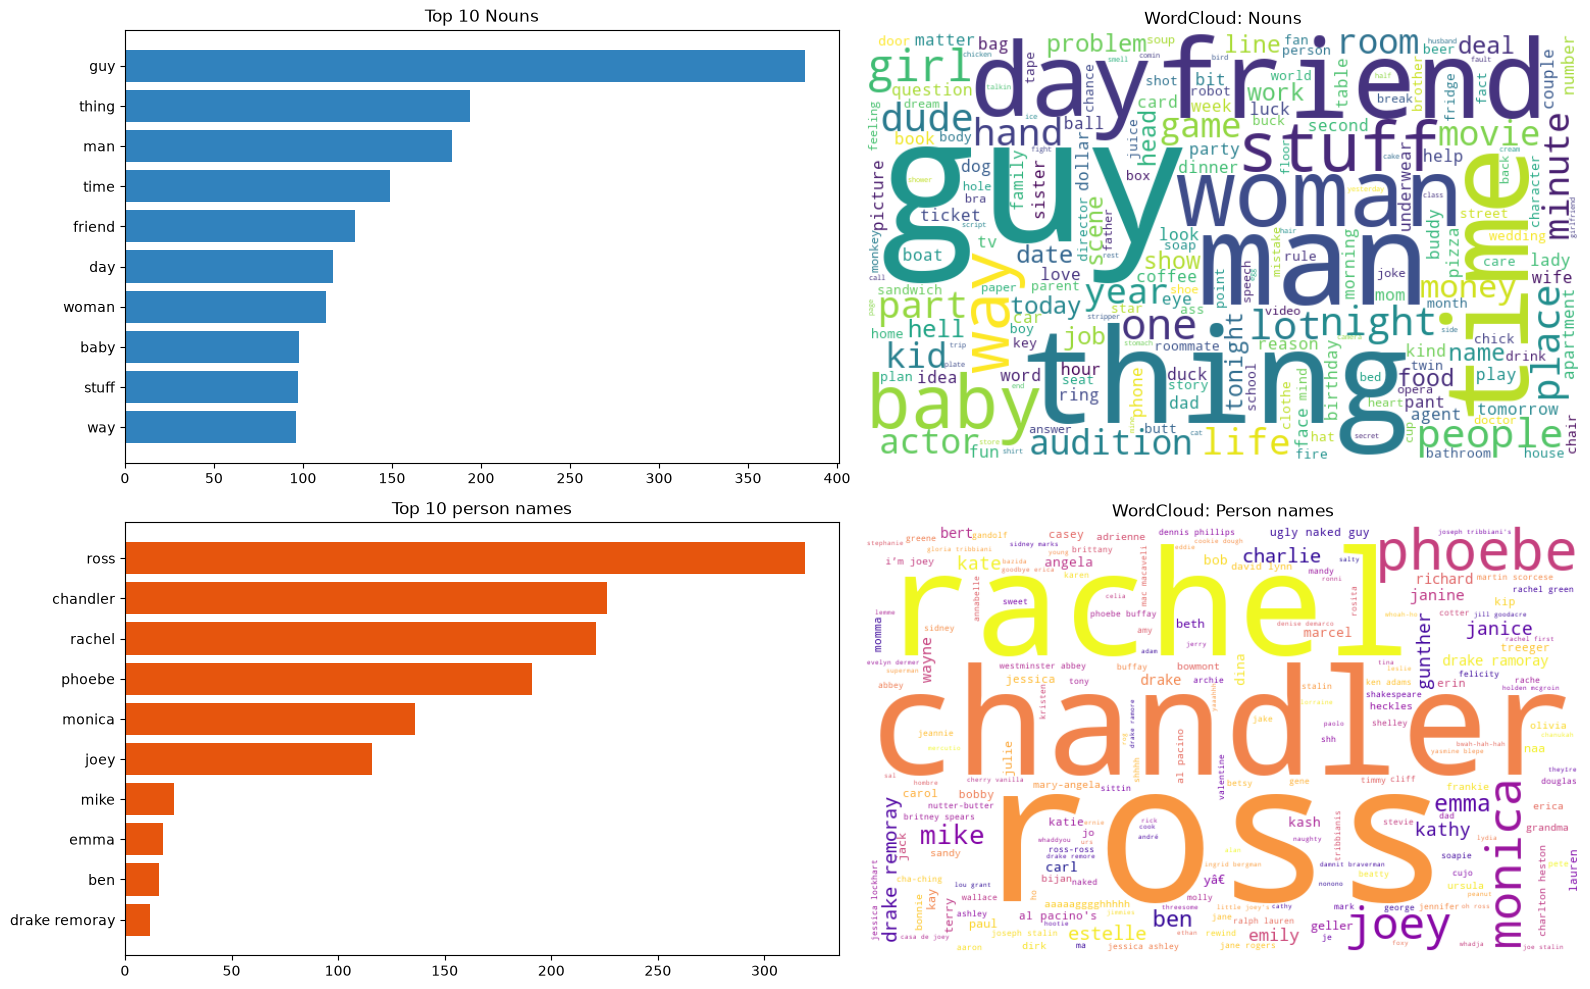

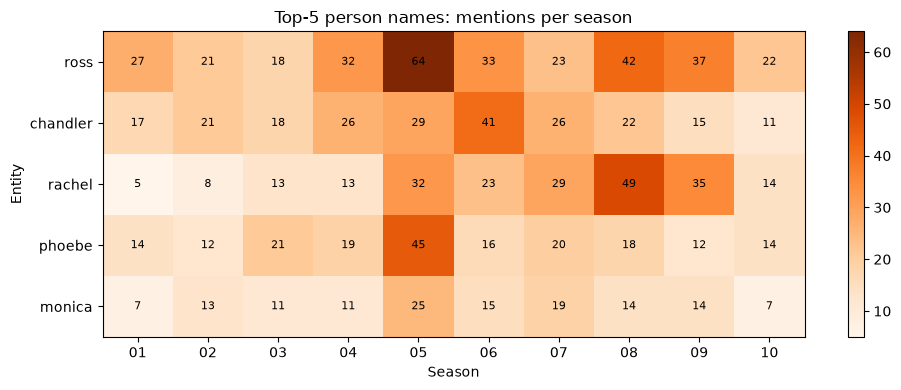

In [13]:
# init spaCy pipeline
nlp = spacy.load('en_core_web_lg')

# add EntityRuler 
ruler = nlp.add_pipe("entity_ruler", before="ner")
patterns = [
    {"label": "LOC",    "pattern": "Central Perk"},
    {"label": "PERSON", "pattern": "Chan-Chan Man"},
    {"label": "PERSON", "pattern": "Pheebs"},
    {"label": "PERSON", "pattern": "Rach"},
    {"label": "PERSON", "pattern": "Mon"}
]
ruler.add_patterns(patterns)

# noise sets
NOT_NOUNS = {"thank", "ohh", "ooh", "whoa", "huh", "hmm", "ah", "yeah"}
NON_PERSON = {"dude", "man", "guys", "guy", "kinda", "mornin", "alright", "congratulations","y'know","ya"}

joey2 = df_raw[df_raw["Speaker"].fillna("").str.strip().str.lower() == "joey"].copy()
joey2["clean_line"] = joey2["Text"].apply(strip_stage_directions)
joey2 = joey2[joey2["clean_line"] != ""].reset_index(drop=True)

docs = list(nlp.pipe(joey2["clean_line"], batch_size=250, disable=["parser"]))

# extract nouns and ners
nouns, entities_all = [], []

for season_label, doc in zip(joey2["Season"], docs):
    for tok in doc:
        if tok.pos_ == "NOUN" and tok.is_alpha:
            lem = tok.lemma_.lower()
            if lem not in nltk_stopwords and lem not in NOT_NOUNS and len(lem) > 1:
                nouns.append((season_label, lem))
    
    for ent in doc.ents:
        if ent.label_ in {"PERSON"}:
            clean_ent = ent.text.strip().lower()
            if clean_ent not in NON_PERSON and len(clean_ent) > 1:
                # apply alias map
                canonical = name_alias_map.get(clean_ent, clean_ent)
                entities_all.append((season_label, canonical, ent.label_))

# aggregate frequencies
noun_counts = Counter(lem for _, lem in nouns)
ent_counts = Counter(ent for _, ent, _ in entities_all)

print(f"Total Nouns extracted: {len(nouns)} ({len(noun_counts)} unique)")
print(f"Total person names extracted: {len(entities_all)} ({len(ent_counts)} unique)")
print("Top 7 Nouns:", noun_counts.most_common(7))
print("Top 7 person names:", ent_counts.most_common(7))

fig, ax = plt.subplots(2, 2, figsize=(16, 10))

top_nouns = pd.DataFrame(noun_counts.most_common(10), columns=["w", "n"]).sort_values("n")
ax[0, 0].barh(top_nouns["w"], top_nouns["n"], color="#3182bd")
ax[0, 0].set_title("Top 10 Nouns")
wc_nouns = WordCloud(width=700, height=420, background_color="white", colormap="viridis").generate_from_frequencies(noun_counts)
ax[0, 1].imshow(wc_nouns, interpolation="bilinear")
ax[0, 1].axis("off")
ax[0, 1].set_title("WordCloud: Nouns")

top_ents = pd.DataFrame(ent_counts.most_common(10), columns=["w", "n"]).sort_values("n")
ax[1, 0].barh(top_ents["w"], top_ents["n"], color="#e6550d")
ax[1, 0].set_title("Top 10 person names")
wc_ents = WordCloud(width=700, height=420, background_color="white", colormap="plasma").generate_from_frequencies(ent_counts)
ax[1, 1].imshow(wc_ents, interpolation="bilinear")
ax[1, 1].axis("off")
ax[1, 1].set_title("WordCloud: Person names")

plt.tight_layout()
plt.show()


top_entities = [ent for ent, _ in ent_counts.most_common(5)]
season_series = pd.Series([s for s, _, _ in entities_all], name="season")
entity_series = pd.Series([e for _, e, _ in entities_all], name="entity")
heat_ent = pd.crosstab(entity_series, season_series).reindex(top_entities).fillna(0)
plt.figure(figsize=(10, 4))
plt.imshow(heat_ent.values, cmap="Oranges", aspect="auto")
plt.xticks(range(heat_ent.shape[1]), [c[-2:] for c in heat_ent.columns])  # Extracts S01, S02... format
plt.yticks(range(heat_ent.shape[0]), heat_ent.index)
for i in range(heat_ent.shape[0]):
    for j in range(heat_ent.shape[1]): plt.text(j, i, int(heat_ent.values[i, j]), ha="center", va="center", fontsize=8)

plt.xlabel("Season")
plt.ylabel("Entity")
plt.title("Top-5 person names: mentions per season")
plt.colorbar()
plt.tight_layout()
plt.show()

**Nouns: 9,446 mentions (1,979 distinct nouns)** Most frequent: guy (382), thing (194), man (184), time (149), friend (129), day (117), woman (113). The top nouns are informal, colloquial words (guy, man, thing), typical of casual dialogue

**Person names: 2,021 mentions (436 distinct names)** Most frequent: ross (319), chandler (226), rachel (221), phoebe (191),  monica (136), joey (116), mike (23)
- Ross, Chandler and Rachel together make up 766 of the 2,021 mentions (38%). The six main characters together make up 1,209 (60%) and the other 812 mentions are spread over about 430 other names.
- Joey mentions Ross most, followed by Chandler and Rachel. Considering that Ross and Chandler are Joey's closest friends, and that Joey and Rachel share a romantic storyline at some point, it makes sense that they are the characters he names more frequently.
- Outside the main six, Mike (Phoebe's boyfriend and later husband) is the most mentioned person

**Per season (heatmap; raw counts)** Ross (64), Phoebe (45) and Monica (25) are mentioned most in Season 5, when Joey finds out about Chandler and Monica's secret relationship before Ross, with Phoebe also involved in keeping the secret. 
Chandler (41) is most mentioned by Joey in Season 6, when they stop being roomies, marking an important moment of their friendship. 
Rachel (49) is most mentioned in season 8, when she moves in with Joey while being pregnant and he start falling in love with her. This is also Ross's second most mentioned season, as he is the father of Rachel's baby, creating a love triangle dynamic that continues into season 9 (the second most mentioned season for Rachel).
Summed over the five names, Season 5 is highest (195 mentions), then Season 8 (145). 